<a href="https://colab.research.google.com/github/mathis-br/Quantum-Compilation/blob/main/Estructure_clean_DirectMethod.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### In this Notebook, one compare the naive qiskit transpilation to the méthod called direct method, derived from https://arxiv.org/pdf/2410.18685, for LiH

In [3]:
!pip install qiskit qiskit-nature pyscf qiskit-algorithms qiskit-aer matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 26.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 65.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 34.5 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 13.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 65.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [qiskit-nature]


In [4]:
# ==============================================================================
#   IMPORTS
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

# --- Qiskit Core & Transpilation ---
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter
from qiskit.visualization import plot_histogram
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import CommutativeCancellation, Optimize1qGatesDecomposition

# --- Qiskit Nature ---
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.operators import FermionicOp
from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit_aer import AerSimulator
from IPython.display import display

# Fix NumPy
np.in1d = np.isin



In [5]:
# Constantes, Set de portes et autres paramètres
BASIS_GATES = ['x', 'sx', 'rz', 'cz']
OPT_LEVEL = 3
TOLERANCE = 1e-10
SEED = 42

def index(i,j): return f'+_{i} -_{j}'

# fonction qui prend en argument en circuit et qui renvoie la depth, le nombre de portes
def analyse(qc, name="Circuit"):
    depth = qc.depth()
    ops = qc.count_ops()
    sorted_ops = sorted(ops.items(), key=lambda item: item[1], reverse=True)
    width = 40
    print(f"\n{f' {name.upper()} ':-^{width}}")
    print(f"DEPTH : {depth}\n" + "-" * width)
    print(f"{'GATE':<18} | {'COUNT':<10}\n" + "=" * width)
    for gate, count in sorted_ops: print(f"{gate:<18} | {count:<10}")
    print("-" * width + "\n")

1/ Transpilation via Qiskit :

One import the Hamiltonian from PySCF, and export it into Pauli Strings, and Transpile it via Qiskit

In [6]:
# ==============================================================================
# CELLULE 2 : RÉSOLUTION PySCF
# ==============================================================================

driver = PySCFDriver(atom="Li 0 0 0; H 0 0 1.45", basis="sto3g")
problem = driver.run()
hamiltonian_fermionic = problem.hamiltonian.second_q_op()
NUM_Q = problem.num_spin_orbitals

mapper = JordanWignerMapper()
H_JW_Exact = SparsePauliOp(
    mapper.map(hamiltonian_fermionic.normal_order()).simplify().chop(1e-14).paulis,
    coeffs=mapper.map(hamiltonian_fermionic.normal_order()).simplify().chop(1e-14).coeffs.real)

# ==============================================================================
# CELLULE 3 : BASELINES JW STANDARD (12Q) ET TAPERED (8Q)
# ==============================================================================
print("⚙️ 1/ Génération de la Référence JW Standard (12 Qubits)...")
pm_expert = PassManager([CommutativeCancellation(), Optimize1qGatesDecomposition(basis=BASIS_GATES)])

qc_jw_raw = QuantumCircuit(NUM_Q)
qc_jw_raw.append(PauliEvolutionGate(H_JW_Exact, time=1.0).definition, range(NUM_Q))
qc_jw_opt = transpile(pm_expert.run(qc_jw_raw), basis_gates=BASIS_GATES, optimization_level=OPT_LEVEL, seed_transpiler=SEED)
analyse(qc_jw_opt, "JW STANDARD (12Q)")

print("⚙️ 2/ Génération de la Référence JW Tapered (8 Qubits)...")
def get_tapered_hamiltonian_auto(mapper, problem):
    tapered_mapper = problem.get_tapered_mapper(mapper)
    return tapered_mapper.map(problem.hamiltonian.second_q_op())

LiH_JW_Tapered = get_tapered_hamiltonian_auto(mapper, problem)
num_q_tap = LiH_JW_Tapered.num_qubits

qc_jw_tap_raw = QuantumCircuit(num_q_tap)
qc_jw_tap_raw.append(PauliEvolutionGate(LiH_JW_Tapered, time=1.0).definition, range(num_q_tap))
qc_JW_tappered = transpile(pm_expert.run(qc_jw_tap_raw), basis_gates=BASIS_GATES, optimization_level=OPT_LEVEL, seed_transpiler=SEED)
analyse(qc_JW_tappered, "JW TAPERED (8Q)")


⚙️ 1/ Génération de la Référence JW Standard (12 Qubits)...

---------- JW STANDARD (12Q) -----------
DEPTH : 15845
----------------------------------------
GATE               | COUNT     
rz                 | 8281      
sx                 | 6901      
cz                 | 4803      
x                  | 2626      
----------------------------------------

⚙️ 2/ Génération de la Référence JW Tapered (8 Qubits)...

----------- JW TAPERED (8Q) ------------
DEPTH : 9553
----------------------------------------
GATE               | COUNT     
rz                 | 4677      
sx                 | 4517      
cz                 | 3061      
x                  | 1387      
----------------------------------------



On utilise la méthode directe, inspiré de : https://arxiv.org/pdf/2410.18685. Pour cela, on va d'abord séparer l'hamiltonien fermionique en hamiltonien à 1 corps (single exitations) et à deux corps (double exitations)

In [7]:

def split_hamiltonian_h1_h2(fermionic_op):
    h1_dict, h2_dict = {}, {}
    for label, coeff in fermionic_op.items():
        if label == "": h1_dict[label] = coeff; continue
        num_ops = len(label.split())
        if num_ops == 2: h1_dict[label] = coeff
        elif num_ops == 4: h2_dict[label] = coeff
    return h1_dict, h2_dict

H_1body, H_2body = split_hamiltonian_h1_h2(hamiltonian_fermionic)


### Décomposition du Hamiltonien Fermionique (Transformation de Jordan-Wigner puis méthode directe)

Dans le cadre de l'Ansatz direct, le Hamiltonien moléculaire est décomposé en 5 sous-Hamiltoniens distincts. L'opérateur d'occupation (qui compte le nombre d'électrons sur une orbitale) est défini par $n_i = a_i^\dagger a_i = \frac{I - Z_i}{2}$.

La transformation de Jordan-Wigner (JW) permet de passer des opérateurs de création/annihilation fermioniques ($a^\dagger, a$) aux matrices de Pauli ($X, Y, Z$) manipulables par les qubits :

* **$H_0$ : Énergies de site (Diagonale à 1 corps)**
    * *Fermionique* : $H_0 = \sum_i h_{ii} n_i$
    * *Jordan-Wigner* : $H_0 = \sum_i \frac{h_{ii}}{2} (I - Z_i)$
    * *Implémentation* : Énergie de base des orbitales, encodée matériellement par de simples rotations un-qubit $R_z$.

* **$H_1$ : Sauts simples / Excitations (Hors-diagonale à 1 corps)**
    * *Fermionique* : $H_1 = \sum_{i < j} h_{ij} (a_i^\dagger a_j + a_j^\dagger a_i)$
    * *Jordan-Wigner* : $H_1 = \sum_{i < j} \frac{h_{ij}}{2} (X_i Z_{i+1} \cdots Z_{j-1} X_j + Y_i Z_{i+1} \cdots Z_{j-1} Y_j)$
    * *Implémentation* : C'est le fameux terme abrégé $XX + YY$. La méthode directe permet d'appliquer ces deux chaînes simultanément via une rotation de Givens native, divisant la profondeur matérielle par deux par rapport à l'approche *Pauli Strings*.

* **$H_2$ : Interaction de Coulomb (Diagonale à 2 corps)**
    * *Fermionique* : $H_2 = \sum_{i < j} h_{ijij} n_i n_j$
    * *Jordan-Wigner* : $H_2 = \sum_{i < j} \frac{h_{ijij}}{4} (I - Z_i - Z_j + Z_i Z_j)$
    * *Implémentation* : Répulsion électrostatique classique entre les électrons. Se traduit par des portes d'interaction de phase pures $R_{zz}$.

* **$H_3$ : Sauts assistés par la densité (Mixte à 2 corps)**
    * *Fermionique* : $H_3 = \sum_{i \neq j \neq k} h_{ijk} (a_i^\dagger n_j a_k + a_k^\dagger n_j a_i)$
    * *Jordan-Wigner* : $H_3 = \sum_{i \neq j \neq k} \frac{h_{ijk}}{4} (X_i \cdots X_k + Y_i \cdots Y_k)(I - Z_j)$
    * *Implémentation* : Un saut d'électron ($XX + YY$) modulé par la présence d'un électron "spectateur" sur l'orbitale $j$. En méthode directe, le spectateur ajoute ou annule algébriquement un opérateur $Z$ dans le masque de parité.

* **$H_4$ : Doubles excitations pures (Hors-diagonale à 2 corps)**
    * *Fermionique* : $H_4 = \sum_{i,j,k,l} h_{ijkl} (a_i^\dagger a_j^\dagger a_k a_l + h.c.)$
    * *Jordan-Wigner* : $H_4 = \sum_{i,j,k,l} \frac{h_{ijkl}}{8} (X_i X_j X_k X_l - X_i X_j Y_k Y_l + \dots) \otimes Z_{parit\acute{e}}$
    * *Implémentation* : En Trotterisation standard, cela génère 8 chaînes de Pauli lourdes. L'Ansatz direct écrase cette complexité en remplaçant ce monstre par un unique bloc d'entanglement optimisé (séquence de Gray Code conditionnée par la parité JW).

Pour la méthode directe, l'article propose une décomposition optimisée des termes H1, H3 et H5, qui réduit le nombre de CNOTs, via un calcul simultané des termes XX et YY

In [8]:
# Extraction H0 et H1
H_0, H_1, processed_pairs = {}, {}, set()
for key in H_1body.keys():
    if key in processed_pairs: continue
    parts = key.split()
    idx_i, idx_j = int(parts[0].split('_')[1]), int(parts[1].split('_')[1])
    if idx_i == idx_j:
        H_0[key] = H_1body[key]; processed_pairs.add(key)
    else:
        key_conjugate = index(idx_j, idx_i)
        H_1[tuple(sorted((idx_i, idx_j)))] = H_1body[key] + H_1body.get(key_conjugate, 0.0)
        processed_pairs.update([key, key_conjugate])

# Extraction H2, H3, H4
H_2, H_3, H_4, processed_keys = {}, {}, {}, set()
for key, coeff in H_2body.items():
    if key in processed_keys: continue
    parts = key.split()
    indices = [int(p.split('_')[1]) for p in parts]
    unique = set(indices)

    if len(unique) == 2:
        H_2[tuple(sorted(list(unique)))] = coeff
        processed_keys.add(key)
    elif len(unique) == 3:
        counts = {idx: indices.count(idx) for idx in indices}
        spectator = [idx for idx, count in counts.items() if count == 2][0]
        jump_indices = sorted([idx for idx, count in counts.items() if count == 1])
        key_conjugate = f"+_{jump_indices[1]} +_{spectator} -_{spectator} -_{jump_indices[0]}"
        H_3[(spectator, tuple(jump_indices))] = coeff + H_2body.get(key_conjugate, 0.0)
        processed_keys.update([key, key_conjugate])
    elif len(unique) == 4:
        cr_indices, ann_indices = sorted(indices[:2]), sorted(indices[2:])
        block_key = tuple(sorted([tuple(cr_indices), tuple(ann_indices)]))
        key_conjugate = f"+_{ann_indices[0]} +_{ann_indices[1]} -_{cr_indices[0]} -_{cr_indices[1]}"
        H_4[block_key] = coeff + H_2body.get(key_conjugate, 0.0)
        processed_keys.update([key, key_conjugate])

print(f"  -> H0: {len(H_0)} | H1: {len(H_1)} | H2: {len(H_2)} | H3: {len(H_3)} | H4: {len(H_4)}")

  -> H0: 12 | H1: 12 | H2: 66 | H3: 120 | H4: 144


On a récupéré les 5 hamiltoniens, on va maintenant les transpilés. H0 et H2 sont transpilés avec qiskit, et les 3 autres via la gate décomposition explicitée à la main, qui provient de l'article. Chaque décomposition à été testée avant (cf notebook ElectronicStructure), pour s'assurer que le circuit obtenu est bien le bon

In [9]:
# ==============================================================================
# CELLULE 3 : ANSATZ DIRECT (MÉTHODE EXACTE ALL-IN-ONE)
# ==============================================================================

# --- 1. GÉNÉRATION DES DIAGONALES ---
def get_diagonal_hamiltonians(H0_dict, H2_dict, num_qubits=12):
    def build_pauli(indices_dict):
        p = ["I"] * num_qubits
        for idx, op in indices_dict.items(): p[num_qubits - 1 - idx] = op
        return "".join(p)

    h0_ops, h0_coeffs = [], []
    for key, val in H0_dict.items():
        idx = int(key.split()[0].split('_')[1])
        h0_ops.extend([build_pauli({}), build_pauli({idx: 'Z'})])
        h0_coeffs.extend([val / 2, -val / 2])

    h2_ops, h2_coeffs = [], []
    for (i, j), val in H2_dict.items():
        h2_ops.extend([build_pauli({}), build_pauli({i: 'Z'}), build_pauli({j: 'Z'}), build_pauli({i: 'Z', j: 'Z'})])
        h2_coeffs.extend([val / 4, -val / 4, -val / 4, val / 4])

    return SparsePauliOp(h0_ops, h0_coeffs).simplify(), SparsePauliOp(h2_ops, h2_coeffs).simplify()

# --- 2. GÉNÉRATION ALGÉBRIQUE H1/H3 (La fameuse étape visuelle indispensable) ---
def get_direct_visual_hamiltonians(H1_dict, H3_dict, num_qubits=12):
    def build_visual_pauli(x_indices, z_indices):
        p = ["I"] * num_qubits
        for z in z_indices: p[num_qubits - 1 - z] = 'Z'
        for x in x_indices: p[num_qubits - 1 - x] = 'X'
        return "".join(p)

    h1_ops, h1_coeffs = [], []
    for (i, j), val in H1_dict.items():
        x_idx = [min(i, j), max(i, j)]
        z_idx = set(range(min(i, j) + 1, max(i, j)))
        h1_ops.append(build_visual_pauli(x_idx, z_idx)); h1_coeffs.append(val)

    h3_ops, h3_coeffs = [], []
    for (k, (i, j)), val in H3_dict.items():
        x_idx = [min(i, j), max(i, j)]
        base_z = set(range(min(i, j) + 1, max(i, j)))
        h3_ops.append(build_visual_pauli(x_idx, base_z)); h3_coeffs.append(val / 2)

        mod_z = set(base_z)
        if k in mod_z: mod_z.remove(k)
        else: mod_z.add(k)
        h3_ops.append(build_visual_pauli(x_idx, mod_z)); h3_coeffs.append(-val / 2)

    return SparsePauliOp(h1_ops, h1_coeffs).simplify(), SparsePauliOp(h3_ops, h3_coeffs).simplify()

# --- 3. FORMATAGE ET CŒURS D'EXCITATION ---
def format_h13_data(H13_visuel):
    data = []
    for label, val in zip(H13_visuel.paulis.to_labels(), H13_visuel.coeffs.real):
        chars = list(reversed(label))
        x_idx = [i for i, c in enumerate(chars) if c in ['X', 'Y']]
        z_idx = [i for i, c in enumerate(chars) if c == 'Z']
        if len(x_idx) >= 2: data.append(((x_idx[0], x_idx[1], z_idx), val))
    return data

def format_h4_data(H_4_dict):
    return [((cre, ann), theta) for (cre, ann), theta in H_4_dict.items()]

def apply_h13_core(qc, idx_i, idx_j, theta, parity_q):
    qc.cx(idx_i, idx_j)
    qc.rz(np.pi/2, idx_i); qc.sx(idx_i); qc.rz(np.pi/2, idx_i)
    if parity_q is not None: qc.cx(parity_q, idx_i)
    qc.rz(theta, idx_i); qc.cx(idx_j, idx_i); qc.rz(-theta, idx_i); qc.cx(idx_j, idx_i)
    if parity_q is not None: qc.cx(parity_q, idx_i)
    qc.rz(np.pi/2, idx_i); qc.sx(idx_i); qc.rz(np.pi/2, idx_i)
    qc.cx(idx_i, idx_j)

def apply_h4_core(qc, c1, c2, a1, a2, theta, parity_q):
    target = a1; ctrls = [a2, c2, c1]; beta = (-2.0 * theta) / 8.0
    qc.cx(a1, a2); qc.cx(c1, c2); qc.cx(a1, c1); qc.x(a2); qc.x(c2)
    if parity_q is not None: qc.cz(parity_q, target)
    qc.ry(beta, target); qc.cx(ctrls[2], target); qc.ry(-beta, target); qc.cx(ctrls[1], target)
    qc.ry(beta, target); qc.cx(ctrls[2], target); qc.ry(-beta, target); qc.cx(ctrls[0], target)
    qc.ry(beta, target); qc.cx(ctrls[2], target); qc.ry(-beta, target); qc.cx(ctrls[1], target)
    qc.ry(beta, target); qc.cx(ctrls[2], target); qc.ry(-beta, target); qc.cx(ctrls[0], target)
    if parity_q is not None: qc.cz(parity_q, target)
    qc.x(a2); qc.x(c2); qc.cx(a1, c1); qc.cx(c1, c2); qc.cx(a1, a2)

# --- 4. ASSEMBLEUR ALL-IN-ONE ---
def build_all_in_one_ansatz(h13_data, h4_data, qc_diag, num_qubits=12):
    qc_exc = QuantumCircuit(num_qubits)
    unified = []
    for (idx_i, idx_j, z_indices), theta in h13_data:
        unified.append({'type':'H13', 'parity_set':set(z_indices), 'params':{'i':idx_i, 'j':idx_j}, 'theta':theta})
    for (cre, ann), theta in h4_data:
        i, j, k, l = sorted(list(cre) + list(ann))
        unified.append({'type':'H4', 'parity_set':set(range(i+1, j)) | set(range(k+1, l)), 'params':{'c':cre, 'a':ann}, 'theta':theta})

    unified.sort(key=lambda x: (sorted(list(x['parity_set'])), x['type']))

    current_parity = set(); current_parity_q = None
    for exc in unified:
        target_parity = exc['parity_set']
        if target_parity != current_parity:
            if len(current_parity) > 1:
                p_list = sorted(list(current_parity))
                for idx in reversed(range(len(p_list)-1)): qc_exc.cx(p_list[idx], p_list[idx+1])
            if len(target_parity) > 1:
                p_list = sorted(list(target_parity))
                for idx in range(len(p_list)-1): qc_exc.cx(p_list[idx], p_list[idx+1])
                current_parity_q = p_list[-1]
            elif len(target_parity) == 1: current_parity_q = list(target_parity)[0]
            else: current_parity_q = None
            current_parity = target_parity

        if exc['type'] == 'H13': apply_h13_core(qc_exc, exc['params']['i'], exc['params']['j'], exc['theta'], current_parity_q)
        else: apply_h4_core(qc_exc, exc['params']['c'][0], exc['params']['c'][1], exc['params']['a'][0], exc['params']['a'][1], exc['theta'], current_parity_q)

    if len(current_parity) > 1:
        p_list = sorted(list(current_parity))
        for idx in reversed(range(len(p_list)-1)): qc_exc.cx(p_list[idx], p_list[idx+1])

    qc_final = QuantumCircuit(num_qubits)
    qc_final.compose(qc_diag, inplace=True); qc_final.compose(qc_exc, inplace=True)
    return qc_final

# --- 5. GÉNÉRATION ET TRANSPILATION ---
print("⚙️ Compilation du circuit QC_ALL_IN_1...")
H0_m, H2_m = get_diagonal_hamiltonians(H_0, H_2)
qc_diag = QuantumCircuit(NUM_Q)
qc_diag.append(PauliEvolutionGate((H0_m + H2_m).simplify(), time=1.0), range(NUM_Q))
qc_transpiled_diag = transpile(qc_diag.decompose(), basis_gates=BASIS_GATES, optimization_level=3)

H1_m_visuel, H3_m_visuel = get_direct_visual_hamiltonians(H_1, H_3)
H13_visuel = (H1_m_visuel + H3_m_visuel).simplify()

qc_final_test_allin1_raw = build_all_in_one_ansatz(format_h13_data(H13_visuel), format_h4_data(H_4), qc_transpiled_diag, NUM_Q)
qc_final_test_allin1 = transpile(qc_final_test_allin1_raw, basis_gates=BASIS_GATES, optimization_level=OPT_LEVEL, seed_transpiler=SEED)

analyse(qc_final_test_allin1, "QC FINAL ALL-IN-1 (H1+H3+H4+DIAG)")

⚙️ Compilation du circuit QC_ALL_IN_1...

-- QC FINAL ALL-IN-1 (H1+H3+H4+DIAG) ---
DEPTH : 9068
----------------------------------------
GATE               | COUNT     
sx                 | 4941      
rz                 | 4251      
cz                 | 3219      
x                  | 1388      
----------------------------------------



Cellule de benchmark : calcule le state vector sur les 3 bases (X, Y et Z) et plot la probabilité de chaque état, et compare à la solution exacte obtenue via la diagonalisation (résuiltat FCI). Il y a des différences à cause de l'erreur de trotter notamment

🔬 Lancement du solveur FCI Exact...

🚀 ANALYSE EN BASE Z (Top 6 états) - 2000000 shots
Fidélité vs FCI :
   • JW Standard (12Q)      : 99.196%
   • Méthode Directe (12Q)  : 91.648%


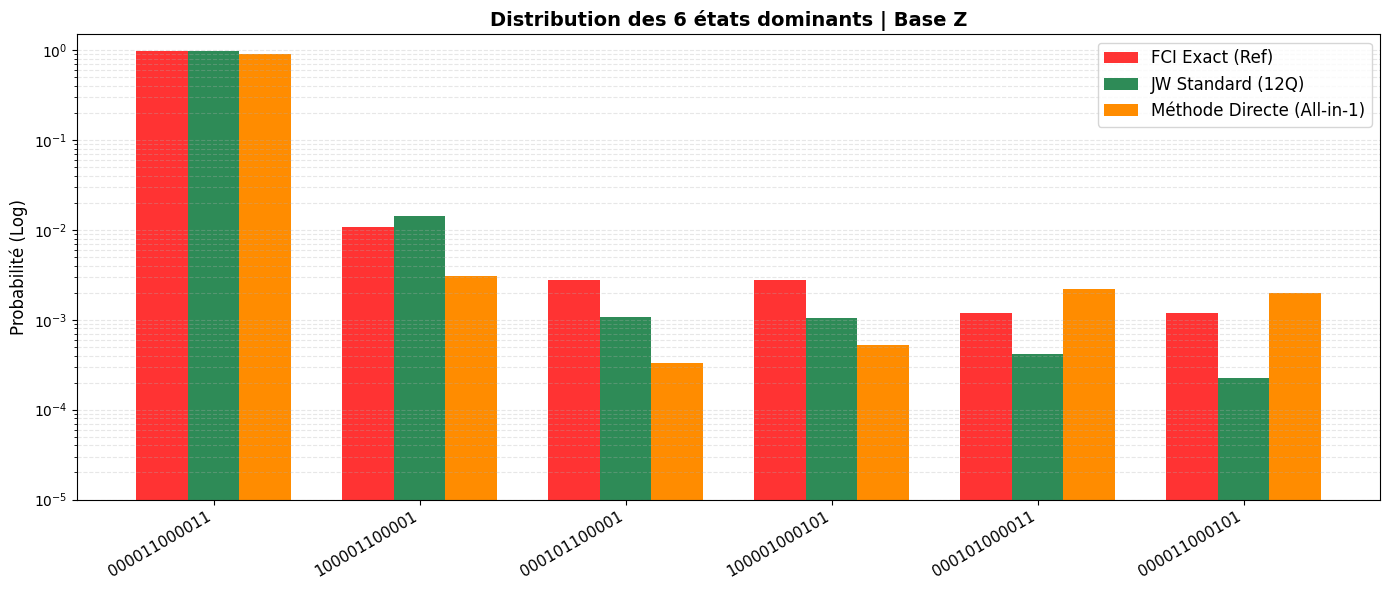


🚀 ANALYSE EN BASE X (Top 6 états) - 2000000 shots
Fidélité vs FCI :
   • JW Standard (12Q)      : 95.109%
   • Méthode Directe (12Q)  : 98.564%


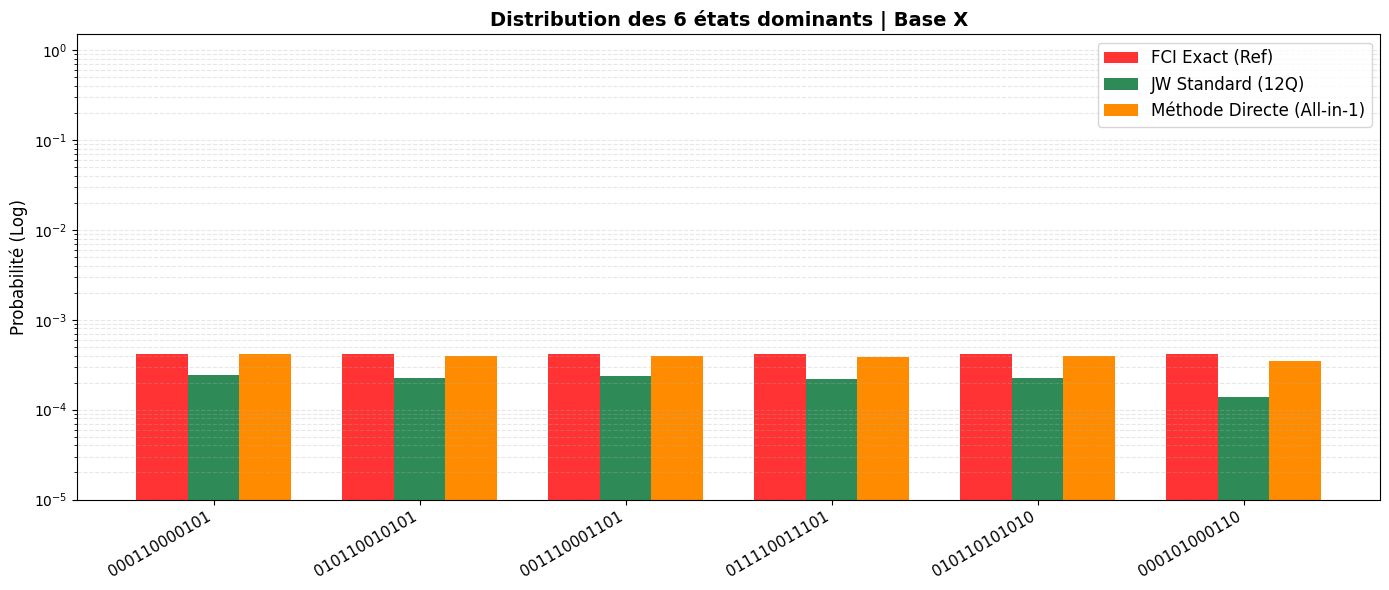


🚀 ANALYSE EN BASE Y (Top 6 états) - 2000000 shots
Fidélité vs FCI :
   • JW Standard (12Q)      : 95.146%
   • Méthode Directe (12Q)  : 98.557%


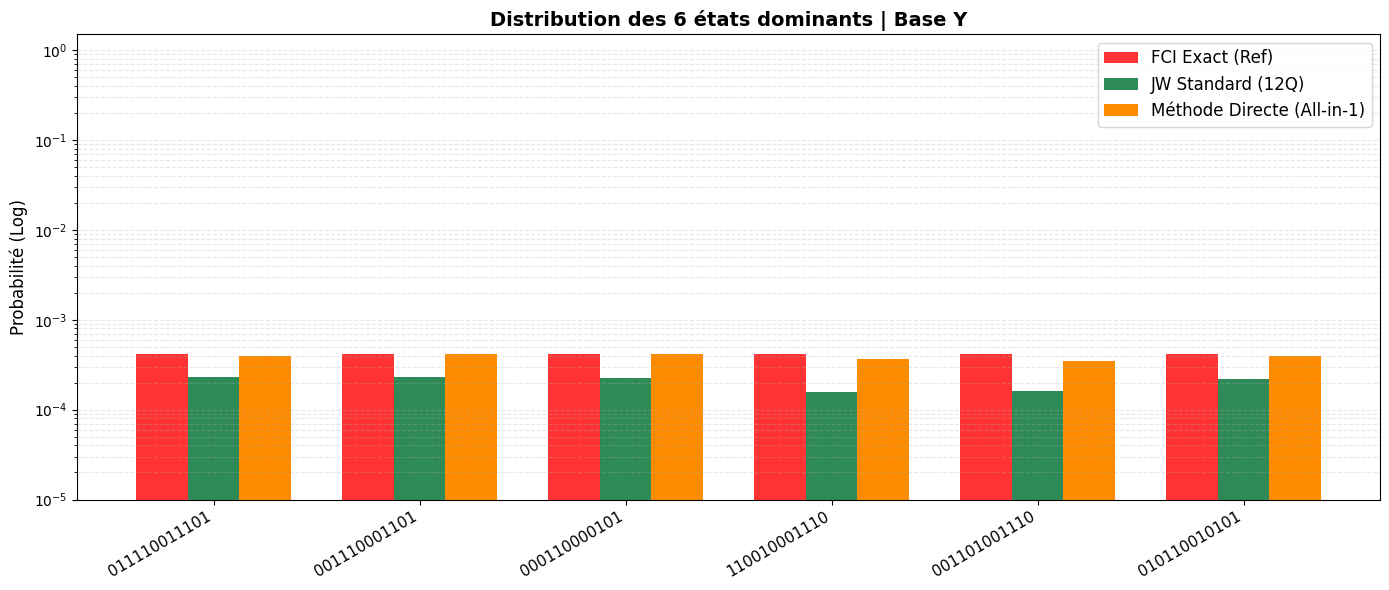

In [10]:
# ==============================================================================
# CELLULE 5 : BENCHMARK MULTI-BASES (FCI vs JW-12Q vs DIRECT-12Q)
# ==============================================================================

def comparaison_absolue_finale(qc_jw, qc_dir, sv_fci, N=100_000, top_n=4, indices_hf=[0, 1, 6, 7]):
    """ Compare les 2 circuits face au Statevector FCI exact sur les bases Z, X, Y. """
    bases = ['Z', 'X', 'Y']
    num_q = qc_jw.num_qubits
    backend = AerSimulator(method='statevector') # Turbo rapide pour de gros shots

    for basis in bases:
        print(f"\n{'='*85}\n🚀 ANALYSE EN BASE {basis} (Top {top_n} états) - {N} shots\n{'='*85}")

        # --- 1. FCI Transformation ---
        qc_fci_trans = QuantumCircuit(num_q)
        if basis == 'X': qc_fci_trans.h(range(num_q))
        elif basis == 'Y': qc_fci_trans.sdg(range(num_q)); qc_fci_trans.h(range(num_q))
        probs_fci = sv_fci.evolve(qc_fci_trans).probabilities_dict()

        # --- 2. Circuits Simulation ---
        def prep_circ(qc_in):
            qc_m = QuantumCircuit(num_q)
            for i in indices_hf: qc_m.x(i)
            qc_m.compose(qc_in, inplace=True)
            if basis == 'X': qc_m.h(range(num_q))
            elif basis == 'Y': qc_m.sdg(range(num_q)); qc_m.h(range(num_q))
            qc_m.measure_all()
            return transpile(qc_m, backend)

        circs_m = [prep_circ(qc_jw), prep_circ(qc_dir)]
        res = backend.run(circs_m, shots=N).result()
        probs_sim = [{k: v/N for k, v in res.get_counts(i).items()} for i in range(2)]

        # --- 3. Fidélité ---
        all_keys = set(probs_fci.keys())
        for i in range(2): all_keys.update(probs_sim[i].keys())

        fid_jw = sum(np.sqrt(probs_fci.get(k,0) * probs_sim[0].get(k,0)) for k in all_keys)**2
        fid_dir = sum(np.sqrt(probs_fci.get(k,0) * probs_sim[1].get(k,0)) for k in all_keys)**2

        print(f"Fidélité vs FCI :")
        print(f"   • JW Standard (12Q)      : {fid_jw*100:.3f}%")
        print(f"   • Méthode Directe (12Q)  : {fid_dir*100:.3f}%")

        # --- 4. Plotting Logarithmique ---
        top_keys = sorted(probs_fci, key=probs_fci.get, reverse=True)[:top_n]
        epsilon = 1e-6
        fci_vals = [max(probs_fci.get(k, 0), epsilon) for k in top_keys]
        v1 = [max(probs_sim[0].get(k, 0), epsilon) for k in top_keys]
        v2 = [max(probs_sim[1].get(k, 0), epsilon) for k in top_keys]

        x = np.arange(len(top_keys)); width = 0.25
        fig, ax = plt.subplots(figsize=(14, 6))
        ax.bar(x - width, fci_vals, width, label='FCI Exact (Ref)', color='red', alpha=0.8)
        ax.bar(x, v1, width, label='JW Standard (12Q)', color='#2E8B57')
        ax.bar(x + width, v2, width, label='Méthode Directe (All-in-1)', color='#FF8C00')

        ax.set_yscale('log'); ax.set_ylim(1e-5, 1.5)
        ax.set_ylabel('Probabilité (Log)', fontsize=12)
        ax.set_title(f"Distribution des {top_n} états dominants | Base {basis}", fontsize=14, fontweight='bold')
        ax.set_xticks(x); ax.set_xticklabels(top_keys, rotation=30, ha='right', fontsize=11)
        ax.legend(fontsize=12, loc='upper right')
        ax.grid(axis='y', which='both', linestyle='--', alpha=0.3)
        plt.tight_layout()
        plt.show()

# Calcul FCI initial (nécessaire pour la validation)
print("🔬 Lancement du solveur FCI Exact...")
sv_fci = Statevector(NumPyMinimumEigensolver().compute_minimum_eigenvalue(H_JW_Exact).eigenstate)

# Lancement de l'analyse
comparaison_absolue_finale(qc_jw_opt, qc_final_test_allin1, sv_fci, N=2_000_000, top_n=6)

Conclusion : Pour les bases X et Y , le nombre inférieur de CNOTs semble donner des résultats meilleurs - Pour la Base Z, c est la depth qui importe le plus pour la fidélité. Ainsi, Il semble qu en fonction des bases les plus importantes, une ou l'autre méthode de transpilation donnera des meilleurs résultats. Or, comme la base Z correspond à l'hamiltonien de Hartree Fock, (qu'on sait résoudre facilement, car il ne prend pas en compte les corellations quantiques), la méthode directe semble plus prometteuse. Ces simulations parfaites doivent néanmoins être mises à l'épreuves de : 1 : les simulations bruitées, 2 : La transpilation Hardware Native (les ajouts de swaps requis dans les différentes méthodes) et enfin : une éventuelleréelle implémentation sur du Hardware

### Conclusion : Arbitrages de Compilation et Perspectives

* **Bases X et Y (Fidélité Algébrique) :** Vulnérables aux erreurs de portes. Stratégie : minimiser le nombre total de CNOTs (méthode *Greedy Parity Network*).
* **Base Z (Fidélité Temporelle) :** Vulnérable à la décohérence ($T_1, T_2$). Stratégie : minimiser la profondeur temporelle du circuit (méthode *Commuting Layers*).
* **Validation matérielle requise (Hardware-Ready) :**
    1. **Simulations bruitées :** Tester les circuits sous modèles d'erreurs réalistes (dépolarisation, relaxation, erreur de lecture).
    2. **Transpilation Native :** Évaluer le surcoût critique induit par l'ajout de portes SWAP selon la topologie.
    3. **Atténuation d'erreurs (EM) :** Appliquer des techniques de correction palliatives (ZNE, Readout Mitigation) sur vrai QPU.
    4. **Optimisation du Layout :** Mapper les orbitales actives sur les meilleurs qubits calibrés du jour.
    5. **CUT OFF:** On a ici considéré toutes les interractions - une simplification en enlevant les interractions inutiles pourrait drastiquement faire chuter la depth, mais avec notre full considération ici : Qui peut le plus peut le moins

***

### Adéquation Matérielle : Stratégies de Compilation par QPU

* **Supraconducteurs (IBM, Google) :** Cohérence courte, topologie restreinte planaire.
  * *Stratégie :* Réduction absolue de la profondeur temporelle et routage optimal pour éviter l'explosion des portes SWAP.
* **Ions Piégés (Quantinuum, IonQ) :** Cohérence longue très longue (ms/s), portes 2Q lentes, connectivité totale (All-to-All). Temps de cohérence long
  * *Stratégie :* Minimisation stricte du nombre d'interactions 2Q (mutualisation maximale) ; la profondeur séquentielle n'est pas pénalisante.